## 1. Khởi tạo Spark

In [1]:
import os, sys

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
# Spark trên Windows cần hadoop.dll trong PATH để ghi file
os.environ["PATH"] = os.path.join(os.environ.get("HADOOP_HOME", r"C:\hadoop"), "bin") + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master("local[*]")
         .appName("RussiaRealEstateEDA")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
# Giao diện chung cho biểu đồ: nền sáng, lưới mảnh, chữ xám
sns.set_theme(style="white", rc={
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
spark.version

'3.5.3'

## 2. Đọc dữ liệu

Đọc dữ liệu đã làm sạch từ `data/clean.parquet` (tạo ở notebook 01) và cache lại vì EDA truy vấn nhiều lần.

In [2]:
CLEAN_PATH = "../data/clean.parquet"
df = spark.read.parquet(CLEAN_PATH).cache()
df.printSchema()

root
 |-- price: long (nullable = true)
 |-- date: string (nullable = true)
 |-- geo_lat: double (nullable = true)
 |-- geo_lon: double (nullable = true)
 |-- region: integer (nullable = true)
 |-- province: string (nullable = true)
 |-- distance_to_capital: double (nullable = true)
 |-- building_type: string (nullable = true)
 |-- pre_owned_house: integer (nullable = true)
 |-- level: integer (nullable = true)
 |-- levels: integer (nullable = true)
 |-- rooms: integer (nullable = true)
 |-- is_studio: integer (nullable = true)
 |-- area: double (nullable = true)
 |-- kitchen_area: double (nullable = true)



10 bản ghi đầu tiên.

In [3]:
df.show(10)

+--------+----------+----------+----------+------+-----------------+-------------------+-------------+---------------+-----+------+-----+---------+-----+------------+
|   price|      date|   geo_lat|   geo_lon|region|         province|distance_to_capital|building_type|pre_owned_house|level|levels|rooms|is_studio| area|kitchen_area|
+--------+----------+----------+----------+------+-----------------+-------------------+-------------+---------------+-----+------+-----+---------+-----+------------+
| 1850000|2018-03-01| 44.996132| 39.074783|  2843|   Krasnodar Krai|  9.451897112322603|        Block|              0|   12|    16|    2|        0| 38.0|         5.0|
|10200000|2018-04-07| 55.655307|37.6146053|     3|           Moscow|  11.17978491225636|   Monolithic|              1|    7|    14|    2|        0| 52.8|        10.0|
| 2500000|2018-04-30|   57.9897| 56.193996|  5520|        Perm Krai|  7.319486752725725|        Brick|              1|    3|     5|    3|        0| 59.0|         6.0

Kích thước dữ liệu.

In [4]:
print(f"Số bản ghi: {df.count():,}")
print(f"Số cột: {len(df.columns)}")

Số bản ghi: 5,470,541
Số cột: 15


## 3. Phân phối các cột số

Boxplot của `price`, `area` (tính trên thang log vì lệch phải mạnh) và `distance_to_capital` (trục symlog để giữ được giá trị 0).

                           count         mean           std  min         1%          25%          50%          75%           99%              max
price               5,470,541.00 4,537,035.41 15,519,251.07 1.00 750,000.00 1,950,000.00 2,990,000.00 4,807,840.00 24,050,000.00 2,147,483,647.00
area                5,470,541.00        53.93         33.29 0.22      19.80        38.00        48.02        63.13        138.10         7,856.00
distance_to_capital 5,470,541.00        28.72         65.30 0.01       0.44         4.71         8.46        18.85        249.82         1,831.32


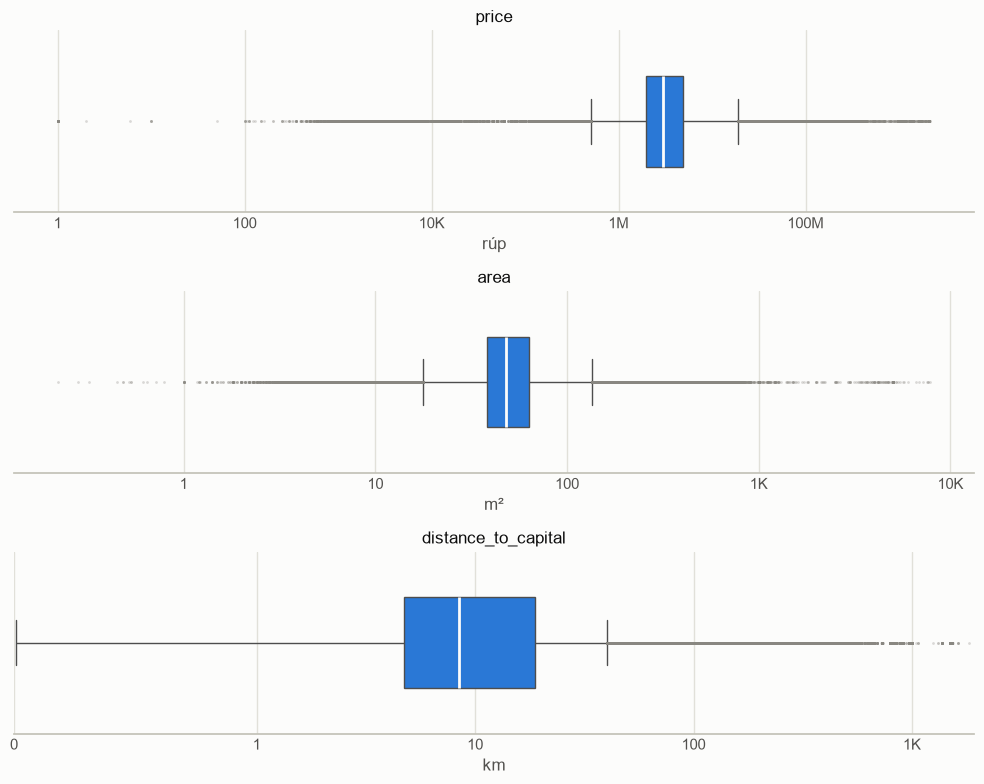

In [5]:
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")
box_cols = {"price": ("rúp", "log"), "area": ("m²", "log"),
            "distance_to_capital": ("km", "symlog")}
box_pdf = df.select(*box_cols).toPandas()
print(box_pdf.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.to_string(float_format="{:,.2f}".format))

human = FuncFormatter(lambda x, _: next((f"{x / d:g}{s}" for d, s in ((1e9, "B"), (1e6, "M"), (1e3, "K")) if abs(x) >= d), f"{x:g}"))
fig, axes = plt.subplots(3, 1, figsize=(10, 8))
for ax, (col, (unit, scale)) in zip(axes, box_cols.items()):
    sns.boxplot(x=box_pdf[col], log_scale=(scale == "log"), color="#2a78d6", saturation=1, width=0.5, ax=ax,
                flierprops={"marker": ".", "markersize": 2, "alpha": 0.3, "markeredgecolor": "#898781"},
                medianprops={"color": "#fcfcfb", "linewidth": 2})
    if scale == "symlog":
        ax.set_xscale("symlog", linthresh=1)
        ax.set_xlim(left=0)
    ax.xaxis.set_major_formatter(human)
    ax.set(xlabel=unit, title=col)
    ax.grid(axis="x", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
sns.despine(left=True)
plt.tight_layout()
plt.show()
del box_pdf

Số bản ghi theo số phòng (`rooms`, 0 là studio) và theo tổng số tầng của tòa nhà (`levels`).

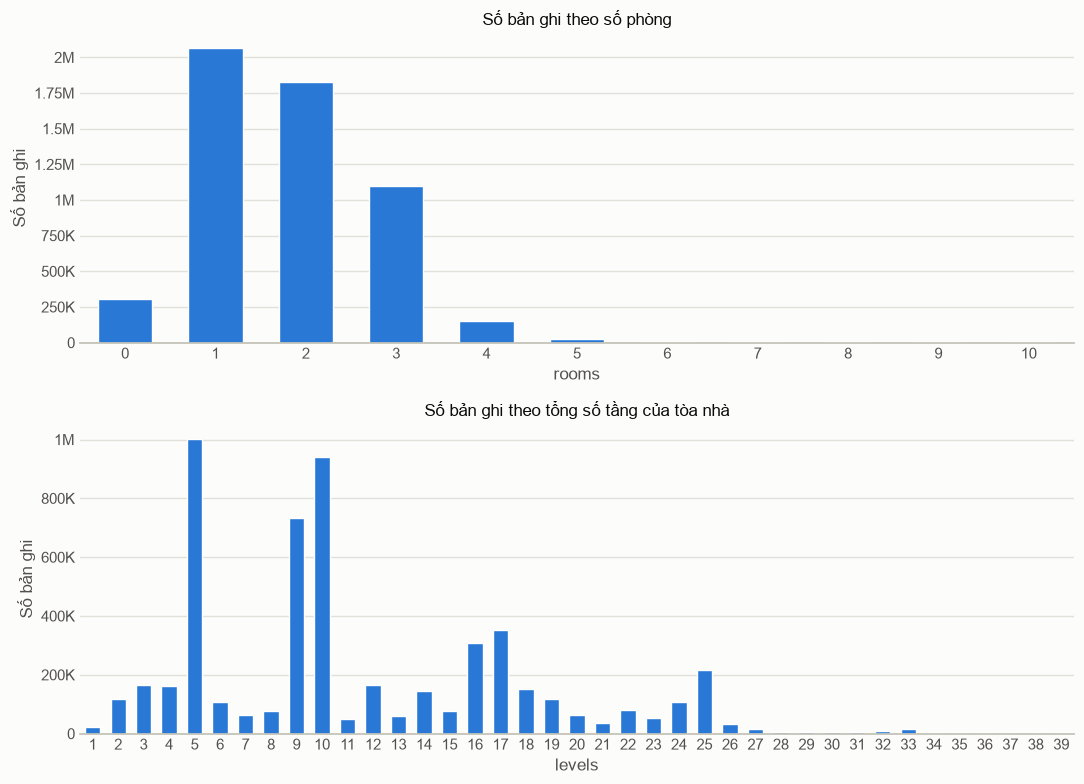

In [6]:
rooms_cnt = df.groupBy("rooms").count().orderBy("rooms").toPandas()
levels_cnt = df.groupBy("levels").count().orderBy("levels").toPandas()

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
for ax, data, col, title in [(axes[0], rooms_cnt, "rooms", "Số bản ghi theo số phòng"),
                             (axes[1], levels_cnt, "levels", "Số bản ghi theo tổng số tầng của tòa nhà")]:
    sns.barplot(data=data, x=col, y="count", color="#2a78d6", saturation=1, width=0.6, ax=ax)
    ax.yaxis.set_major_formatter(human)
    ax.set(xlabel=col, ylabel="Số bản ghi", title=title)
    ax.grid(axis="y", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
sns.despine(left=True)
plt.tight_layout()
plt.show()

## 4. Phân bố bản ghi và giá theo vùng

Top 10 vùng (chủ thể liên bang) có nhiều bản ghi nhất và 10 vùng có ít bản ghi nhất (hai trục hoành khác thang đo).

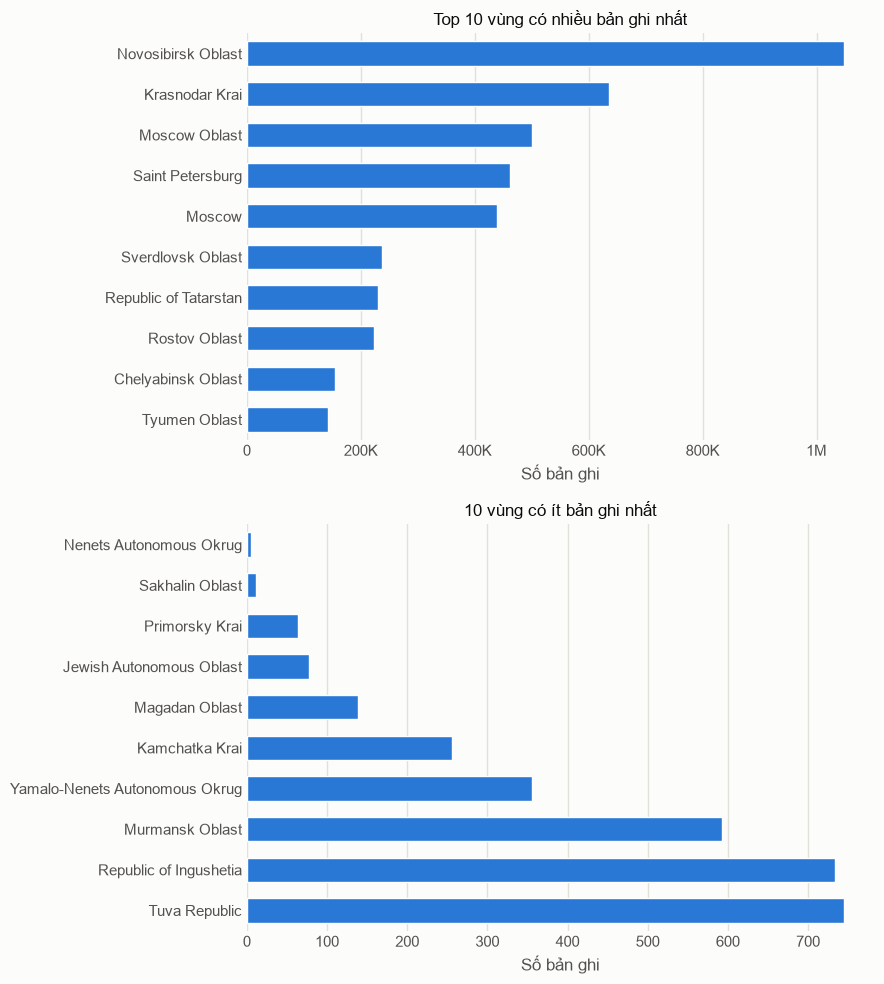

In [7]:
prov_counts = df.groupBy("province").count().toPandas()
top_prov = prov_counts.nlargest(10, "count")
bottom_prov = prov_counts.nsmallest(10, "count")

compact = FuncFormatter(lambda x, _: next((f"{x / d:g}{s}" for d, s in ((1e9, "B"), (1e6, "M"), (1e3, "K")) if abs(x) >= d), f"{x:g}"))
fig, axes = plt.subplots(2, 1, figsize=(9, 10))
for ax, data, title in [(axes[0], top_prov, "Top 10 vùng có nhiều bản ghi nhất"),
                        (axes[1], bottom_prov, "10 vùng có ít bản ghi nhất")]:
    sns.barplot(data=data, x="count", y="province", color="#2a78d6", width=0.6, saturation=1, ax=ax)
    ax.xaxis.set_major_formatter(compact)
    ax.set(xlabel="Số bản ghi", ylabel=None, title=title)
    ax.grid(axis="x", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Top 10 vùng có giá trung vị (`price`) cao nhất và 10 vùng có giá trung vị thấp nhất.

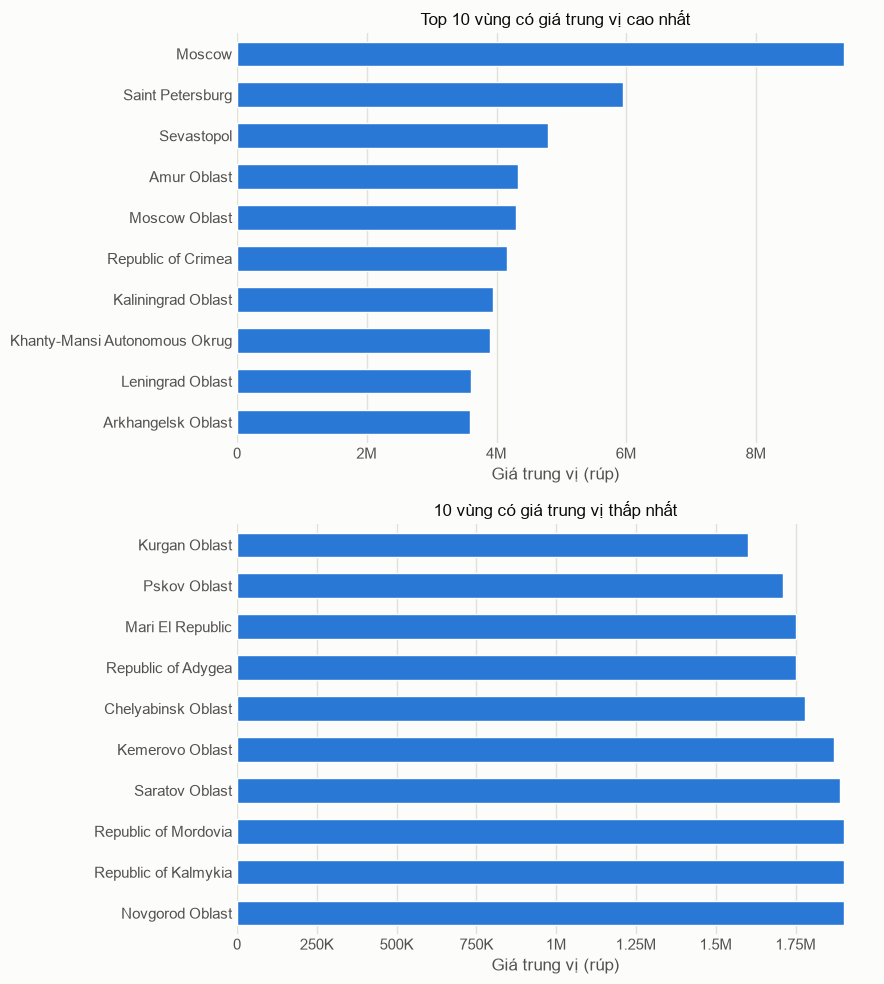

In [8]:
median_price = (df.groupBy("province")
                  .agg(F.median("price").alias("median_price"), F.count("*").alias("count"))
                  .toPandas())
top_med = median_price.nlargest(10, "median_price")
bottom_med = median_price.nsmallest(10, "median_price")

fig, axes = plt.subplots(2, 1, figsize=(9, 10))
for ax, data, title in [(axes[0], top_med, "Top 10 vùng có giá trung vị cao nhất"),
                        (axes[1], bottom_med, "10 vùng có giá trung vị thấp nhất")]:
    sns.barplot(data=data, x="median_price", y="province", color="#2a78d6", width=0.6, saturation=1, ax=ax)
    ax.xaxis.set_major_formatter(compact)
    ax.set(xlabel="Giá trung vị (rúp)", ylabel=None, title=title)
    ax.grid(axis="x", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Phân vị giá (`price`) của Moscow, Saint Petersburg và các vùng còn lại.

In [9]:
price_group = F.when(F.col("province").isin("Moscow", "Saint Petersburg"), F.col("province")).otherwise("Phần còn lại")
group_pct = (df.groupBy(price_group.alias("group"))
               .agg(F.count("*").alias("count"), F.percentile("price", [0.0, 0.01, 0.25, 0.5, 0.75, 0.99, 1.0]).alias("p"))
               .toPandas())
group_pct[["P0", "P1", "P25", "P50", "P75", "P99", "P100"]] = pd.DataFrame(group_pct.pop("p").tolist())
group_pct = group_pct.set_index("group").loc[["Moscow", "Saint Petersburg", "Phần còn lại"]]
group_pct.index.name = None
(group_pct.style
    .format(precision=0, thousands=".")
    .set_table_styles([{"selector": "", "props": "border-collapse: collapse;"},
                       {"selector": "th, td", "props": "border: 1px solid #c3c2b7; padding: 4px 12px; text-align: right;"}]))

,count,P0,P1,P25,P50,P75,P99,P100
Moscow,438.906,1,2.590.000,6.960.940,9.350.000,13.500.000,80.859.500,1.096.745.000
Saint Petersburg,461.303,1,2.150.000,4.400.000,5.950.000,8.800.000,41.209.800,1.945.382.704
Phần còn lại,4.570.332,1,700.000,1.800.000,2.600.000,3.804.750,11.500.000,2.147.483.647


Giá tại các phân vị 99 đến 100 và 0 đến 1 (bước 0,1) của `price` cho Moscow, Saint Petersburg và các vùng còn lại.

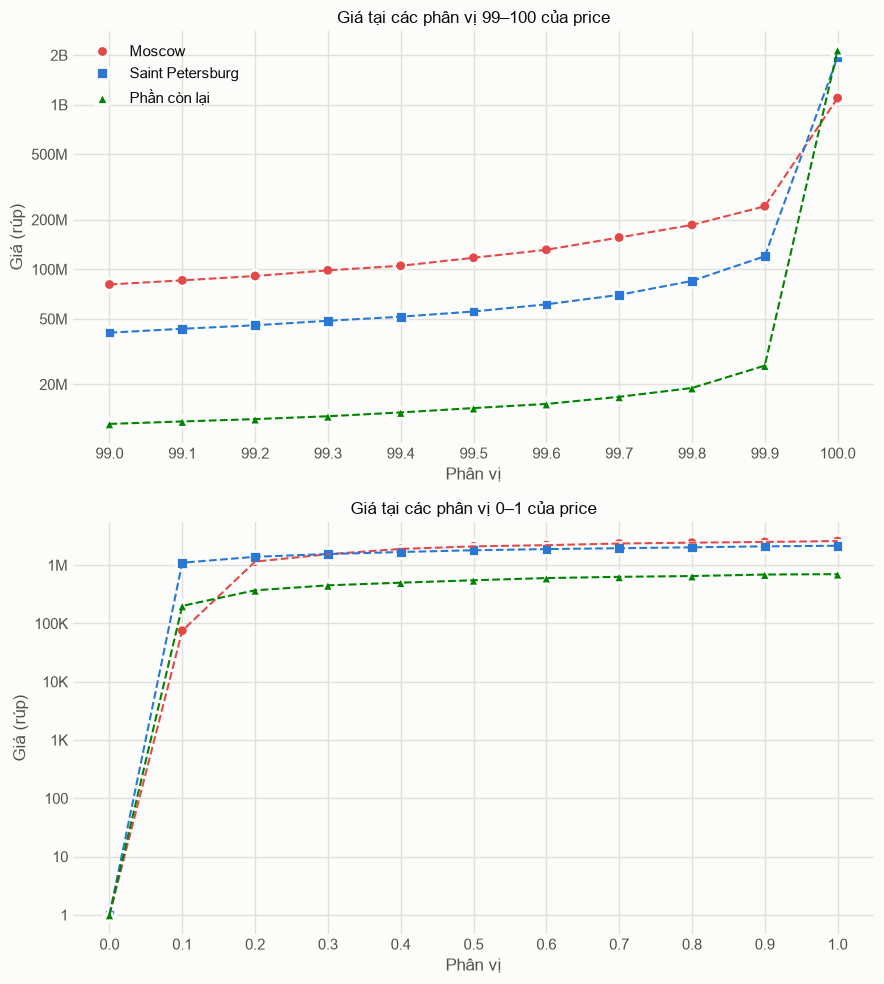

In [10]:
pct_sets = {"99–100": [round(99 + 0.1 * i, 1) for i in range(11)],
            "0–1": [round(0.1 * i, 1) for i in range(11)]}
levels = pct_sets["99–100"] + pct_sets["0–1"]
group_order = ["Moscow", "Saint Petersburg", "Phần còn lại"]
group_colors = {"Moscow": "#e34948", "Saint Petersburg": "#2a78d6", "Phần còn lại": "#008300"}
group_markers = {"Moscow": "o", "Saint Petersburg": "s", "Phần còn lại": "^"}

pct_rows = (df.groupBy(price_group.alias("group"))
              .agg(F.percentile("price", [p / 100 for p in levels]).alias("v"))
              .collect())
pct_df = pd.DataFrame([(r["group"], p, v) for r in pct_rows for p, v in zip(levels, r["v"])],
                      columns=["group", "percentile", "price"])

def log_ticks(lo, hi):
    steps = (1, 2, 5) if hi / lo < 1e4 else (1,)
    return [m * 10 ** e for e in range(11) for m in steps if lo <= m * 10 ** e <= hi]

fig, axes = plt.subplots(2, 1, figsize=(9, 10))
for ax, (name, lv) in zip(axes, pct_sets.items()):
    data = pct_df[pct_df["percentile"].isin(lv)]
    sns.lineplot(data=data, x="percentile", y="price", hue="group", hue_order=group_order, palette=group_colors,
                 linestyle="--", linewidth=1.5, errorbar=None, legend=False, ax=ax)
    sns.scatterplot(data=data, x="percentile", y="price", hue="group", style="group", hue_order=group_order,
                    style_order=group_order, palette=group_colors, markers=group_markers, s=70,
                    edgecolor="#fcfcfb", linewidth=2, legend=(ax is axes[0]), ax=ax)
    ax.set_yscale("log")
    ax.set_yticks(log_ticks(data["price"].min(), data["price"].max()))
    ax.minorticks_off()
    ax.yaxis.set_major_formatter(compact)
    ax.set_xticks(lv)
    ax.set(xlabel="Phân vị", ylabel="Giá (rúp)", title=f"Giá tại các phân vị {name} của price")
    ax.grid(linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
axes[0].legend(title=None, frameon=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Ở đầu trên, giá của cả ba nhóm tăng đều tới phân vị 99,9 rồi vọt lên 1–2 tỷ rúp ở phân vị 100. Ở đầu dưới, giá thấp nhất chỉ 1 rúp; đường giá ổn định từ phân vị 0,1 với Saint Petersburg và các vùng còn lại, còn với Moscow phải từ phân vị 0,2. Các điểm gãy này được dùng làm ngưỡng cắt ngoại lai của `price` ở notebook 03.

Giá mỗi m² (`price_per_m2 = price / area`) và tương quan Spearman với các đặc trưng còn lại (tính trên toàn bộ dữ liệu). 

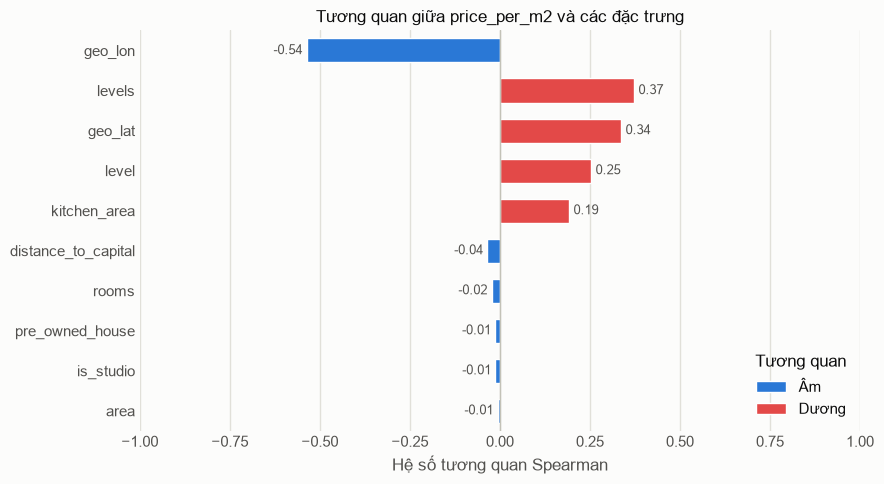

In [11]:
df = df.withColumn("price_per_m2", F.col("price") / F.col("area"))
ppm2_feats = ["area", "kitchen_area", "rooms", "level", "levels", "geo_lat", "geo_lon",
              "distance_to_capital", "is_studio", "pre_owned_house"]
# Spearman = Pearson trên thứ hạng; mỗi lần chỉ kéo 2 cột về pandas để nhẹ bộ nhớ mà vẫn dùng toàn bộ dữ liệu
rows = []
for col in ppm2_feats:
    pair = df.select("price_per_m2", col).toPandas()
    rows.append((col, pair["price_per_m2"].rank().corr(pair[col].rank())))
del pair
ppm2_corr = pd.DataFrame(rows, columns=["feature", "spearman"]).sort_values("spearman", key=abs, ascending=False)
ppm2_corr["sign"] = np.where(ppm2_corr["spearman"] < 0, "Âm", "Dương")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ppm2_corr, x="spearman", y="feature", hue="sign", hue_order=["Âm", "Dương"],
            palette={"Âm": "#2a78d6", "Dương": "#e34948"}, width=0.6, saturation=1, dodge=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, color="#52514e", fontsize=9)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlim(-1, 1)
ax.set(xlabel="Hệ số tương quan Spearman", ylabel=None, title="Tương quan giữa price_per_m2 và các đặc trưng")
ax.legend(title="Tương quan", frameon=False, loc="lower right")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Phân phối giá mỗi m² của Moscow, Saint Petersburg và các vùng còn lại (boxplot trên toàn bộ dữ liệu, tính trên thang log, không vẽ điểm ngoại lai để dễ so sánh).

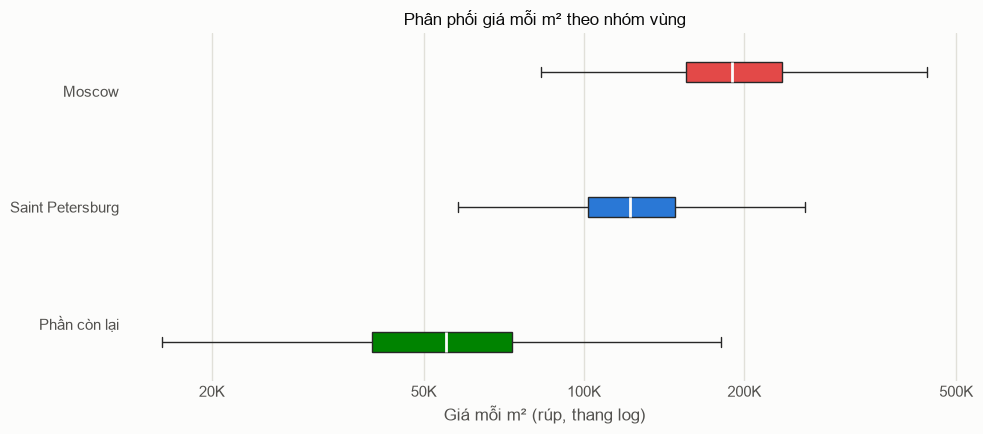

In [12]:
# Nhóm vùng kéo về dưới dạng mã 0/1/2 (1 byte) rồi đổi thành category: nhẹ hơn nhiều so với cột chuỗi
group_code = (F.when(F.col("province") == "Moscow", 0)
               .when(F.col("province") == "Saint Petersburg", 1).otherwise(2).cast("byte"))
ppm2_pdf = df.select(group_code.alias("code"), "price_per_m2").toPandas()
ppm2_pdf["group"] = pd.Categorical.from_codes(ppm2_pdf.pop("code"), categories=group_order)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=ppm2_pdf, x="price_per_m2", y="group", order=group_order, hue="group", hue_order=group_order,
            palette=group_colors, log_scale=True, width=0.5, saturation=1, showfliers=False, legend=False,
            medianprops={"color": "#fcfcfb", "linewidth": 2}, ax=ax)
ax.set_xticks([2e4, 5e4, 1e5, 2e5, 5e5])
ax.minorticks_off()
ax.xaxis.set_major_formatter(compact)
ax.set(xlabel="Giá mỗi m² (rúp, thang log)", ylabel=None, title="Phân phối giá mỗi m² theo nhóm vùng")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()
del ppm2_pdf

Giá mỗi m² trung vị ở Moscow khoảng 190 nghìn rúp, gấp khoảng 1,6 lần Saint Petersburg (122 nghìn) và 3,5 lần các vùng còn lại (55 nghìn). Hộp của các vùng còn lại rộng nhất vì nhóm này gộp nhiều thị trường có mặt bằng giá rất khác nhau, còn giá ở hai thành phố lớn tập trung hơn.

Top 10 vùng có tương quan Spearman giữa `price` và `distance_to_capital` mạnh nhất

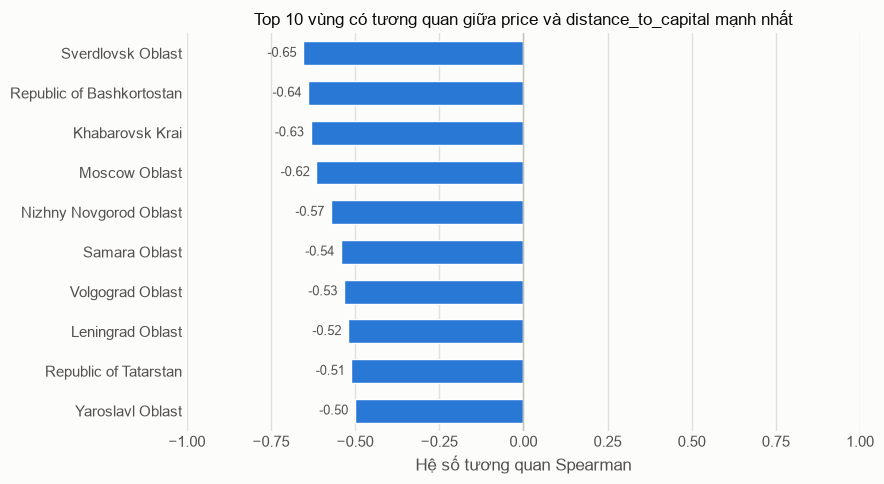

In [13]:
from pyspark.sql import Window

def avg_rank(col):
    """Hạng trung bình trong từng vùng (các giá trị bằng nhau nhận hạng trung bình), dùng cho Spearman."""
    return (F.rank().over(Window.partitionBy("province").orderBy(col))
            + (F.count("*").over(Window.partitionBy("province", col)) - 1) / 2)

region_corr = (df.select("province", avg_rank("price").alias("r_price"), avg_rank("distance_to_capital").alias("r_dist"))
                 .groupBy("province")
                 .agg(F.count("*").alias("count"), F.corr("r_price", "r_dist").alias("spearman"))
                 .toPandas())
big = region_corr[region_corr["count"] >= 1000]
top_corr = big.loc[big["spearman"].abs().sort_values(ascending=False).index[:10]]
top_corr["sign"] = np.where(top_corr["spearman"] < 0, "Âm", "Dương")
signs = [s for s in ["Âm", "Dương"] if s in set(top_corr["sign"])]

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_corr, x="spearman", y="province", hue="sign", hue_order=signs,
            palette={"Âm": "#2a78d6", "Dương": "#e34948"}, width=0.6, saturation=1, dodge=False,
            legend=len(signs) > 1, ax=ax)
for bar, v in zip(ax.patches, top_corr["spearman"]):
    ax.text(v + (-0.02 if v < 0 else 0.02), bar.get_y() + bar.get_height() / 2, f"{v:.2f}",
            va="center", ha="right" if v < 0 else "left", color="#52514e", fontsize=9)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlim(-1, 1)
ax.set(xlabel="Hệ số tương quan Spearman", ylabel=None,
       title="Top 10 vùng có tương quan giữa price và distance_to_capital mạnh nhất")
if len(signs) > 1:
    ax.legend(title="Tương quan", frameon=False, loc="lower right")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Các vùng có tương quan Spearman dương giữa `price` và `distance_to_capital` (xét mọi vùng, kèm số bản ghi).

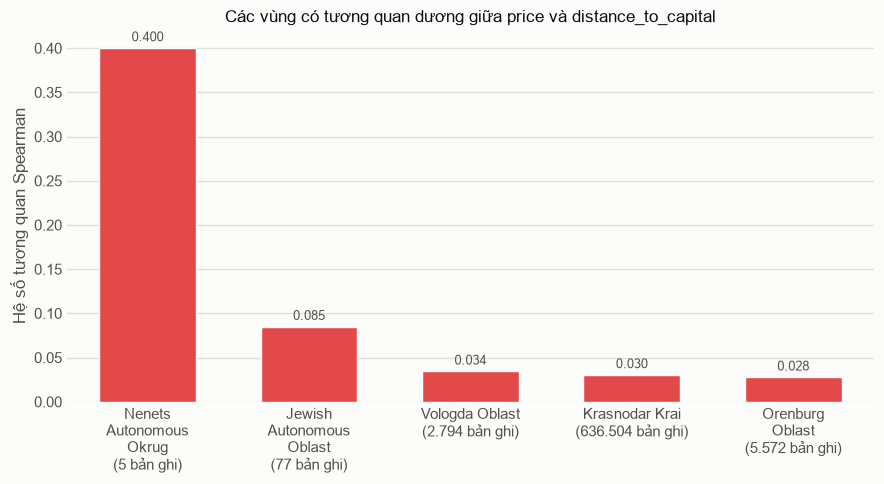

In [14]:
import textwrap

pos_corr = region_corr[region_corr["spearman"] > 0].sort_values("spearman", ascending=False)
pos_corr["label"] = [f"{textwrap.fill(p, 14)}\n({n:,} bản ghi)".replace(",", ".")
                     for p, n in zip(pos_corr["province"], pos_corr["count"])]

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=pos_corr, x="label", y="spearman", color="#e34948", width=0.6, saturation=1, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3, color="#52514e", fontsize=9)
ax.set(xlabel=None, ylabel="Hệ số tương quan Spearman", title="Các vùng có tương quan dương giữa price và distance_to_capital")
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Tương quan dương ở các vùng này đều không đáng kể. Nenets có hệ số cao (+0,40) chỉ vì có quá ít bản ghi (5).

## 5. Giá theo đặc điểm căn hộ

Phân vị của `price` theo `building_type`, `pre_owned_house` và `is_studio`.

In [15]:
q_levels = [0.01, 0.25, 0.5, 0.75, 0.99]
q_cols = ["P1", "P25", "P50", "P75", "P99"]
table_style = [{"selector": "", "props": "border-collapse: collapse;"},
               {"selector": "th, td", "props": "border: 1px solid #c3c2b7; padding: 4px 12px; text-align: right;"},
               {"selector": "caption", "props": "caption-side: top; font-weight: bold; text-align: left; padding-bottom: 4px;"}]

def price_pct_by(col):
    t = (df.groupBy(col)
           .agg(F.count("*").alias("count"), F.percentile("price", q_levels).alias("p"))
           .orderBy(col)
           .toPandas())
    t[q_cols] = pd.DataFrame(t.pop("p").tolist())
    return t.set_index(col).rename_axis(None)

for col in ["building_type", "pre_owned_house", "is_studio"]:
    display(price_pct_by(col).style
              .format(precision=0, thousands=".")
              .set_caption(f"Theo {col}")
              .set_table_styles(table_style))

,count,P1,P25,P50,P75,P99
Block,174.215,560.000,1.890.000,2.700.000,4.000.000,13.500.000
Brick,1.890.040,650.000,1.900.000,2.820.000,4.400.000,22.200.000
Monolithic,1.129.698,1.220.099,3.070.020,4.620.000,7.600.000,42.000.000
Others,306.929,1.100.000,2.600.000,3.750.000,5.544.970,28.962.330
Panel,1.953.360,836.145,1.669.000,2.400.000,3.700.000,13.200.000
Wooden,16.299,129.900,750.000,1.200.000,2.000.000,14.750.808


,count,P1,P25,P50,P75,P99
0,1.611.014,980.000,1.850.000,3.100.000,5.400.240,25.341.731
1,3.859.527,670.000,1.990.000,2.950.000,4.600.000,23.500.000


,count,P1,P25,P50,P75,P99
0,5.164.658,750.000,2.000.000,3.050.000,4.970.000,24.800.000
1,305.883,770.000,1.320.000,1.890.000,3.000.000,9.570.169


Nhà loại `Monolithic` có giá trung vị cao nhất, khoảng 4,6 triệu rúp, và đuôi trên dài nhất (phân vị 99 là 42 triệu); nhà `Wooden` rẻ nhất với trung vị 1,2 triệu, còn `Panel`, `Brick` và `Block` ở mức 2,4–2,8 triệu. Giá trung vị của nhà mới và nhà đã qua sử dụng gần như bằng nhau (3,10 và 2,95 triệu), dù giá nhà mới phân tán rộng hơn. Căn studio rẻ hơn rõ rệt, trung vị 1,89 triệu so với 3,05 triệu của các căn còn lại.

Tỷ lệ các giá trị của `building_type` và `pre_owned_house` ở Moscow, Saint Petersburg và các vùng còn lại (mỗi cột là một nhóm vùng, mỗi hàng là một biến).

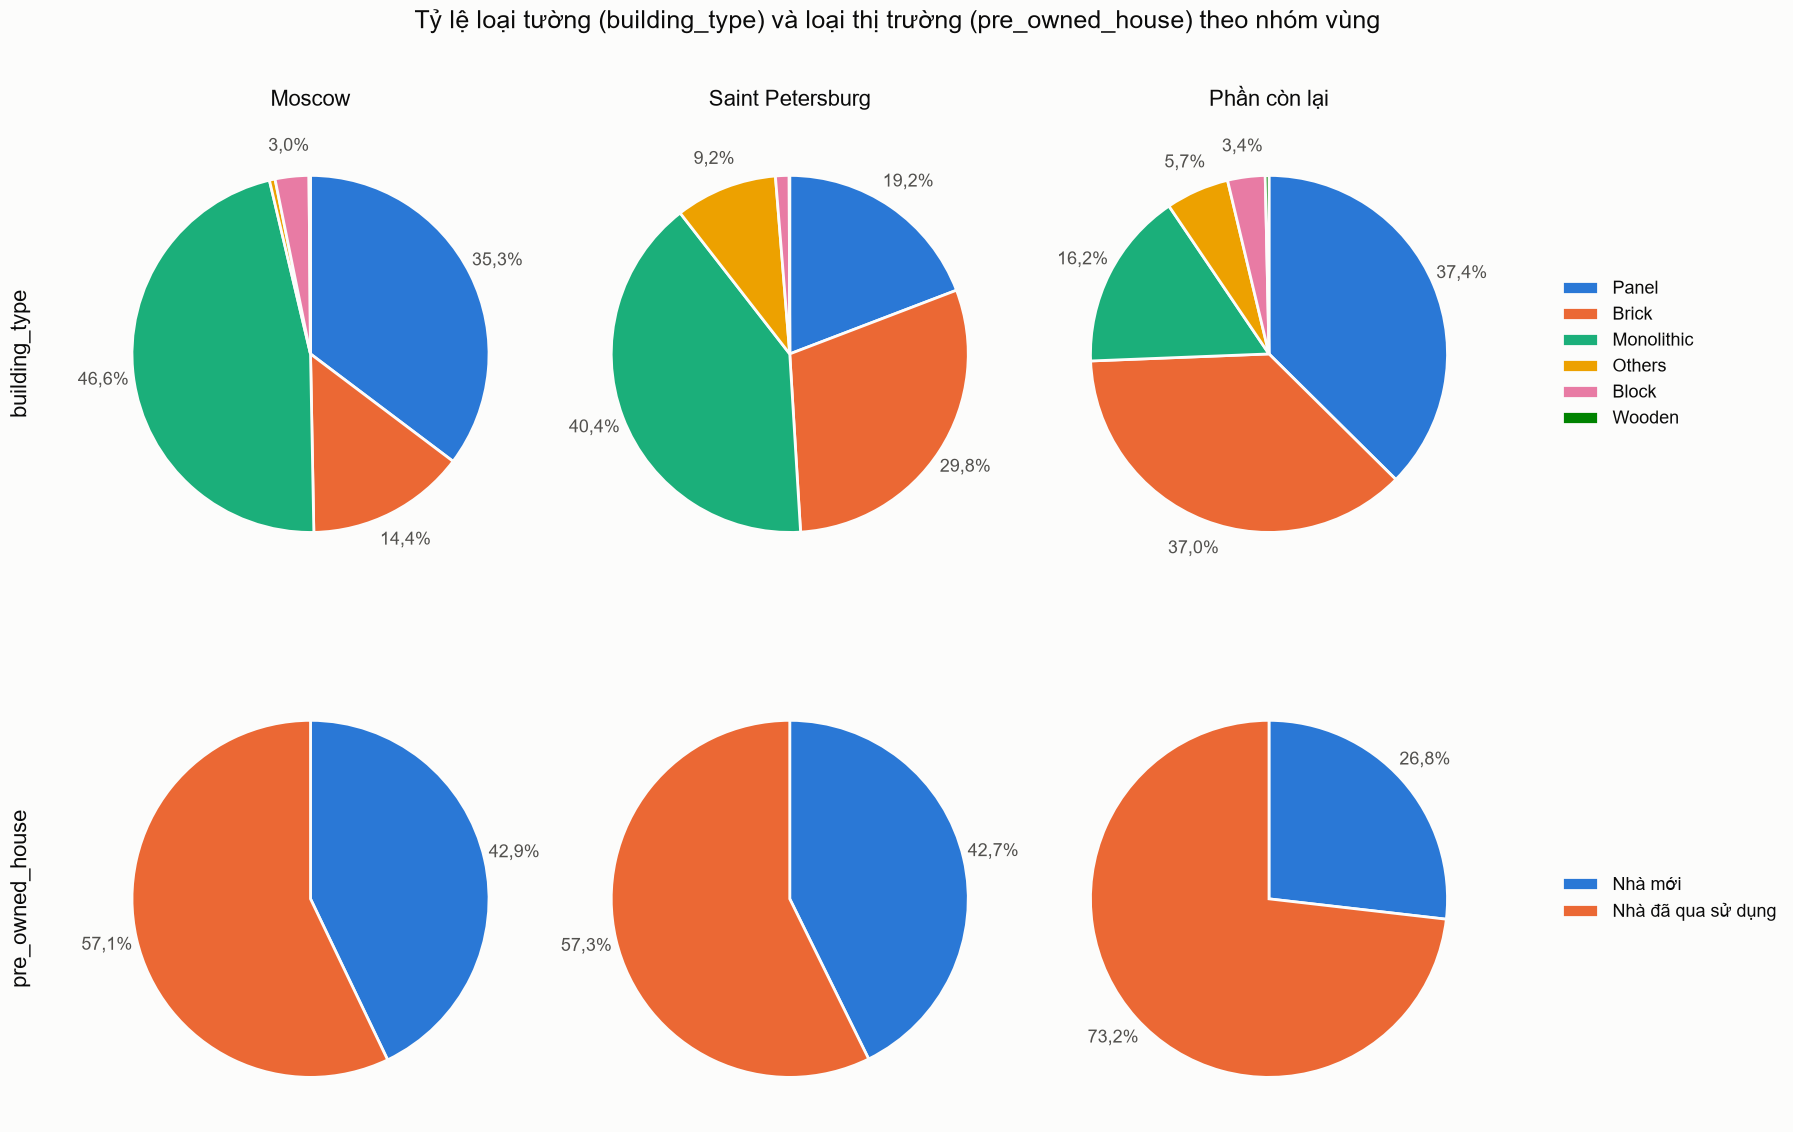

In [16]:
pie_labels = {"building_type": None,
              "pre_owned_house": {0: "Nhà mới", 1: "Nhà đã qua sử dụng"}}
pie_orders = {"building_type": ["Panel", "Brick", "Monolithic", "Others", "Block", "Wooden"],
              "pre_owned_house": ["Nhà mới", "Nhà đã qua sử dụng"]}
pie_palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

pie_counts = {}
for col, labels in pie_labels.items():
    t = df.groupBy(price_group.alias("group"), col).count().toPandas()
    if labels:
        t[col] = t[col].map(labels)
    pie_counts[col] = t.pivot(index="group", columns=col, values="count").fillna(0)

fig, axes = plt.subplots(len(pie_labels), len(group_order), figsize=(18, 12))
for r, col in enumerate(pie_labels):
    for c, g in enumerate(group_order):
        ax, order = axes[r, c], pie_orders[col]
        # nhãn phần trăm đặt ngoài vòng tròn, bỏ qua lát dưới 2% (vẫn có trong chú thích)
        wedges, _, _ = ax.pie(pie_counts[col].loc[g, order], colors=pie_palette[:len(order)], startangle=90,
                              counterclock=False, autopct=lambda p: f"{p:.1f}%".replace(".", ",") if p >= 2 else "",
                              pctdistance=1.17, wedgeprops={"linewidth": 2, "edgecolor": "#fcfcfb"},
                              textprops={"fontsize": 13, "color": "#52514e"})
        if r == 0:
            ax.set_title(g, fontsize=16, pad=18)
        if c == 0:
            ax.text(-0.15, 0.5, col, transform=ax.transAxes, rotation=90, ha="center", va="center", fontsize=16)
        if c == len(group_order) - 1:
            ax.legend(wedges, order, loc="center left", bbox_to_anchor=(1.12, 0.5), frameon=False, fontsize=13)
fig.suptitle("Tỷ lệ loại tường (building_type) và loại thị trường (pre_owned_house) theo nhóm vùng", fontsize=18)
plt.tight_layout()
plt.show()

Nhà `Monolithic` chiếm tỷ lệ lớn nhất ở Moscow (46,6%) và Saint Petersburg (40,4%), còn ở các vùng còn lại chủ yếu là `Panel` (37,4%) và `Brick` (37,0%), `Monolithic` chỉ 16,2%. Nhà mới chiếm khoảng 43% bản ghi ở hai thành phố lớn nhưng chỉ 26,8% ở các vùng còn lại. Do đó giá cao của nhà `Monolithic` ở bảng trên một phần có thể đến từ việc loại nhà này tập trung ở Moscow và Saint Petersburg.

## 6. Tương quan giữa các cột số

Ma trận tương quan Spearman (dựa trên thứ hạng, ít bị ảnh hưởng bởi giá trị ngoại lai) của các cột bản chất là số (không gồm mã `region` và các cột nhị phân), tính trên toàn bộ dữ liệu.

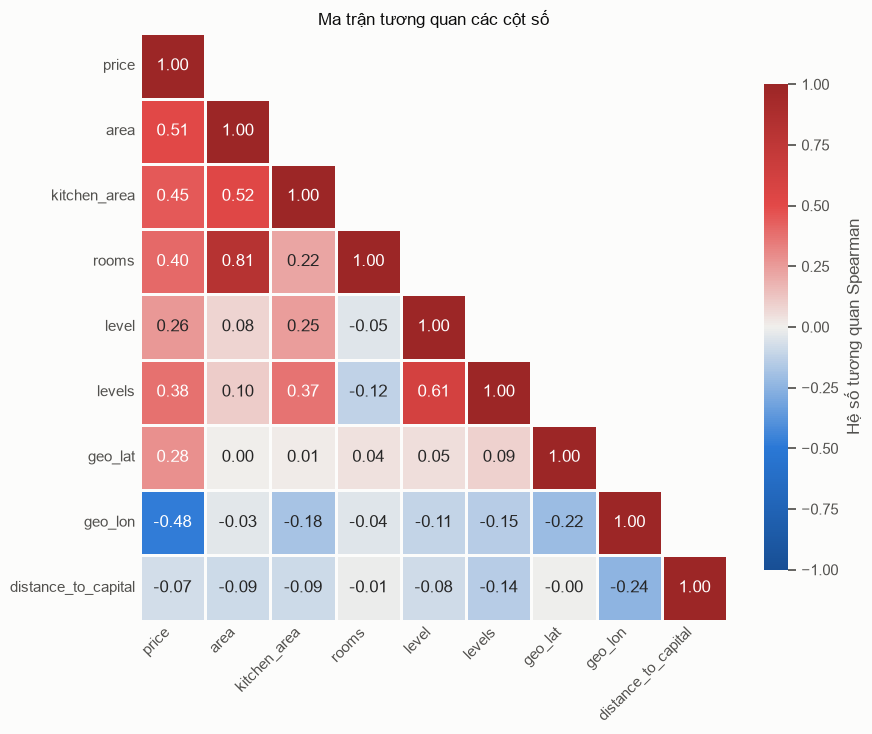

In [17]:
from matplotlib.colors import LinearSegmentedColormap

num_cols = ["price", "area", "kitchen_area", "rooms", "level", "levels",
            "geo_lat", "geo_lon", "distance_to_capital"]
# Spearman = Pearson trên thứ hạng: kéo các cột về một lần (float32 cho nhẹ), đổi từng cột thành thứ hạng tại chỗ
ranks = df.select([F.col(c).cast("float") for c in num_cols]).toPandas()
for col in num_cols:
    ranks[col] = ranks[col].rank().astype("float32")
corr = ranks.corr()
del ranks

# Thang màu phân kỳ: xanh (âm) - xám trung tính (0) - đỏ (dương)
cmap = LinearSegmentedColormap.from_list("blue_red", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#9c2626"])
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", square=True, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"shrink": 0.8, "label": "Hệ số tương quan Spearman"}, ax=ax)
ax.set_title("Ma trận tương quan các cột số")
ax.tick_params(length=0)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

`price` tương quan mạnh nhất với `area` (0,51) và `geo_lon` (−0,48, giá giảm dần về phía đông), tiếp đến `kitchen_area` (0,45), `rooms` (0,40) và `levels` (0,38). Một số cặp đặc trưng tương quan chặt với nhau, như `rooms` với `area` (0,81) và `level` với `levels` (0,61). `distance_to_capital` gần như không tương quan với `price` trên toàn bộ dữ liệu (−0,07) vì quan hệ này khác nhau giữa các vùng (mục 4).

Scatter giữa `rooms` và `area` trên mẫu ngẫu nhiên 1% bản ghi; các điểm được dịch ngang ngẫu nhiên để không chồng lên nhau trong cùng số phòng, trục tung thang log.

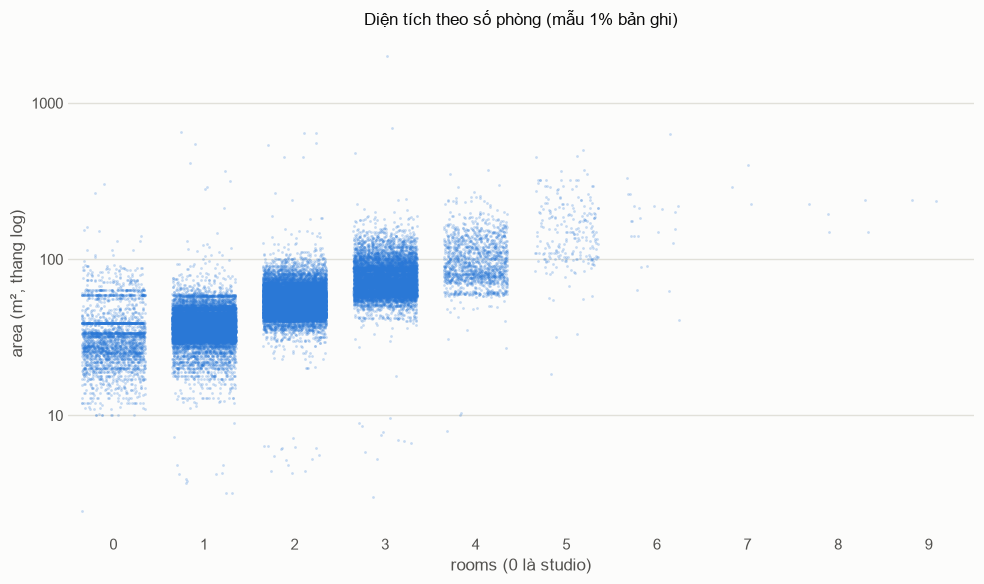

In [18]:
rooms_area = df.select("rooms", "area").sample(fraction=0.01, seed=42).toPandas()

fig, ax = plt.subplots(figsize=(10, 6))
sns.stripplot(data=rooms_area, x="rooms", y="area", jitter=0.35, size=2, alpha=0.25, color="#2a78d6", ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set(xlabel="rooms (0 là studio)", ylabel="area (m², thang log)", title="Diện tích theo số phòng (mẫu 1% bản ghi)")
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Diện tích tăng theo số phòng, từ trung vị 32,5 m² ở studio lên 38, 54, 73 và 90 m² ở căn 1–4 phòng, nhưng các nhóm chồng lấn nhau đáng kể; căn từ 5 phòng trở lên chỉ chiếm khoảng 0,5% bản ghi. Các dải ngang ở nhóm studio là những diện tích lặp lại rất nhiều lần, như 33,58 m² với 21.781 bản ghi. Ngoài ra còn khoảng 6 nghìn bản ghi có diện tích dưới 10 m² hoặc trên 500 m², bất thường so với số phòng.

## 7. Giá theo thời gian

Giá trung bình (`price`) theo tháng của Moscow, Saint Petersburg và các vùng còn lại, chỉ gồm các tháng có trên 500 bản ghi trong mỗi nhóm.

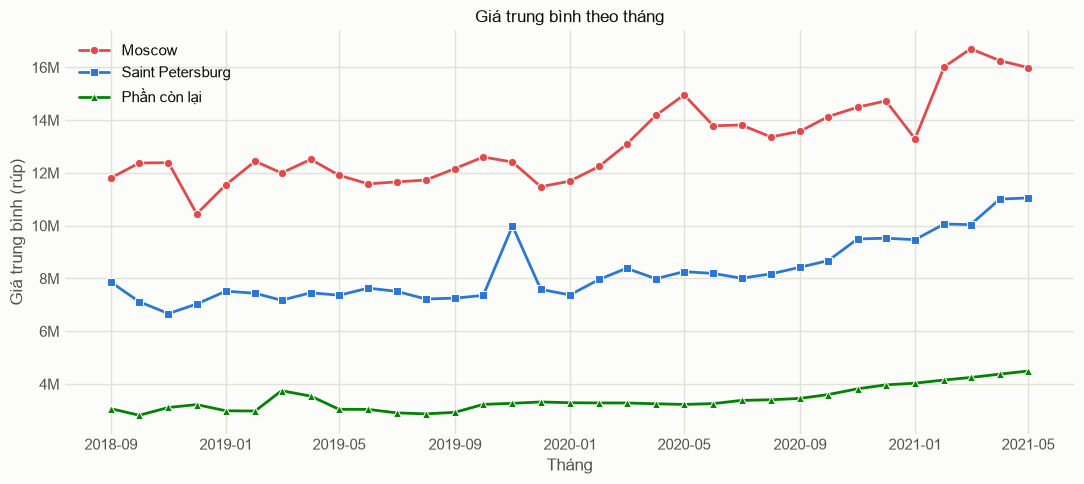

In [19]:
monthly = (df.groupBy(F.substring("date", 1, 7).alias("month"), price_group.alias("group"))
             .agg(F.avg("price").alias("avg_price"), F.count("*").alias("count"))
             .filter(F.col("count") > 500)
             .orderBy("month")
             .toPandas())
monthly["month"] = pd.to_datetime(monthly["month"])

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly, x="month", y="avg_price", hue="group", style="group", hue_order=group_order,
             style_order=group_order, palette=group_colors, markers=group_markers, dashes=False,
             linewidth=2, markersize=6, ax=ax)
ax.yaxis.set_major_formatter(compact)
ax.set(xlabel="Tháng", ylabel="Giá trung bình (rúp)", title="Giá trung bình theo tháng")
ax.legend(title=None, loc="upper left", frameon=False)
ax.grid(linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Từ 09/2018 đến hết năm 2019, giá trung bình của cả ba nhóm gần như đi ngang: Moscow quanh 11,5–12,5 triệu rúp, Saint Petersburg quanh 7–8 triệu và các vùng còn lại quanh 3 triệu. Giá bắt đầu tăng từ năm 2020 nhưng không cùng lúc: Moscow tăng mạnh trong nửa đầu năm (từ 11,7 triệu tháng 01 lên 15,0 triệu tháng 05) rồi chững lại quanh 13,4–14,7 triệu, Saint Petersburg tăng dần từ đầu năm và nhanh hơn từ cuối năm, còn các vùng còn lại đứng yên quanh 3,3 triệu đến giữa năm rồi tăng đều; sang đầu năm 2021 cả ba nhóm tiếp tục tăng.

Tính từ 09/2018 đến 04/2021, giá trung bình tăng 37,7% ở Moscow, 40,1% ở Saint Petersburg và 42,7% ở các vùng còn lại, tức mức tăng khá gần nhau, khoảng 1,4 lần. Các điểm nhô lên hoặc tụt xuống chỉ trong một tháng, như Saint Petersburg tháng 11/2019 (10,0 triệu) hay Moscow tháng 12/2018 và 01/2021, là dao động ngắn hạn: giá trung bình chịu ảnh hưởng của cơ cấu căn hộ được rao trong tháng nên không phản ánh xu hướng.